**Lab 5 Linear_Regression_OLS_and_GD**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Dataset: Height (X) and Weight (y)
X = np.array([0.5, 2.3, 2.9])
y = np.array([1.4, 1.9, 3.2])

print("Dataset loaded successfully!")
print("Height (X):", X)
print("Weight (y):", y)

Dataset loaded successfully!
Height (X): [0.5 2.3 2.9]
Weight (y): [1.4 1.9 3.2]


In [2]:
def ols_linear_regression(X, y):
    """
    Compute linear regression parameters analytically using OLS closed-form formulas.
    """
    # 1. Compute mean of X and mean of y
    x_mean = np.mean(X)
    y_mean = np.mean(y)
    
    # 2. Compute numerator and denominator for slope 'm'
    numerator = np.sum((X - x_mean) * (y - y_mean))
    denominator = np.sum((X - x_mean) ** 2)
    m = numerator / denominator
    
    # 3. Compute intercept 'c'
    c = y_mean - m * x_mean
    
    return m, c

print("OLS function defined!")

OLS function defined!


In [3]:
def gradient_descent(X, y, alpha=0.05, epochs=1500):
    """
    Optimize linear regression parameters using batch gradient descent.
    """
    m = 0.0
    c = 0.0
    n = len(X)
    loss_history = []
    
    for epoch in range(epochs):
        # 1. Compute predictions: y_hat = m * X + c
        y_pred = m * X + c
        
        # 2. Compute Mean Squared Error (MSE) loss
        loss = (1 / n) * np.sum((y_pred - y) ** 2)
        loss_history.append(loss)
        
        # 3. Compute partial derivatives (gradients)
        dm = (2 / n) * np.sum((y_pred - y) * X)
        dc = (2 / n) * np.sum(y_pred - y)
        
        # 4. Update parameters m and c
        m = m - alpha * dm
        c = c - alpha * dc
        
    return m, c, loss_history

print("Gradient Descent function defined!")

Gradient Descent function defined!


In [4]:
def compute_evaluation_metrics(X, y, y_pred, m):
    """
    Calculate R-squared and statistical significance (p-value) of the slope.
    """
    n = len(X)
    df = n - 2  # degrees of freedom (3 - 2 = 1)
    
    # 1. Calculate SS_res (Residual sum of squares) and SS_tot (Total sum of squares)
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    
    # 2. Calculate R-squared (R2)
    r2 = 1 - (ss_res / ss_tot)
    
    # 3. Calculate Standard Error of the slope SE(m)
    residual_variance = ss_res / df
    se_m = np.sqrt(residual_variance / np.sum((X - np.mean(X)) ** 2))
    
    # 4. Compute t-statistic (t = m / se_m)
    t_stat = m / se_m
    
    # 5. Compute two-tailed p-value using Student's t survival function (sf)
    p_val = 2 * stats.t.sf(np.abs(t_stat), df)
    
    return r2, t_stat, p_val

print("Evaluation metrics function defined!")

Evaluation metrics function defined!


In [5]:
# --- 1. Execute OLS ---
m_ols, c_ols = ols_linear_regression(X, y)
y_pred_ols = m_ols * X + c_ols
r2_ols, t_ols, p_ols = compute_evaluation_metrics(X, y, y_pred_ols, m_ols)

print("==================== OLS RESULTS ====================")
print(f"Equation   : y = {m_ols:.4f}x + {c_ols:.4f}")
print(f"R-squared  : {r2_ols:.4f}")
print(f"t-statistic: {t_ols:.4f}")
print(f"p-value    : {p_ols:.4f}\n")

# --- 2. Execute Gradient Descent ---
alpha = 0.05
epochs = 1500
m_gd, c_gd, losses = gradient_descent(X, y, alpha=alpha, epochs=epochs)
y_pred_gd = m_gd * X + c_gd
r2_gd, t_gd, p_gd = compute_evaluation_metrics(X, y, y_pred_gd, m_gd)

print("============== GRADIENT DESCENT RESULTS ==============")
print(f"Equation   : y = {m_gd:.4f}x + {c_gd:.4f}")
print(f"R-squared  : {r2_gd:.4f}")
print(f"t-statistic: {t_gd:.4f}")
print(f"p-value    : {p_gd:.4f}\n")

==================== OLS RESULTS ====================
Equation   : y = 0.6410x + 0.9487
R-squared  : 0.7425
t-statistic: 1.6981
p-value    : 0.3388

============== GRADIENT DESCENT RESULTS ==============
Equation   : y = 0.6410x + 0.9487
R-squared  : 0.7425
t-statistic: 1.6981
p-value    : 0.3388



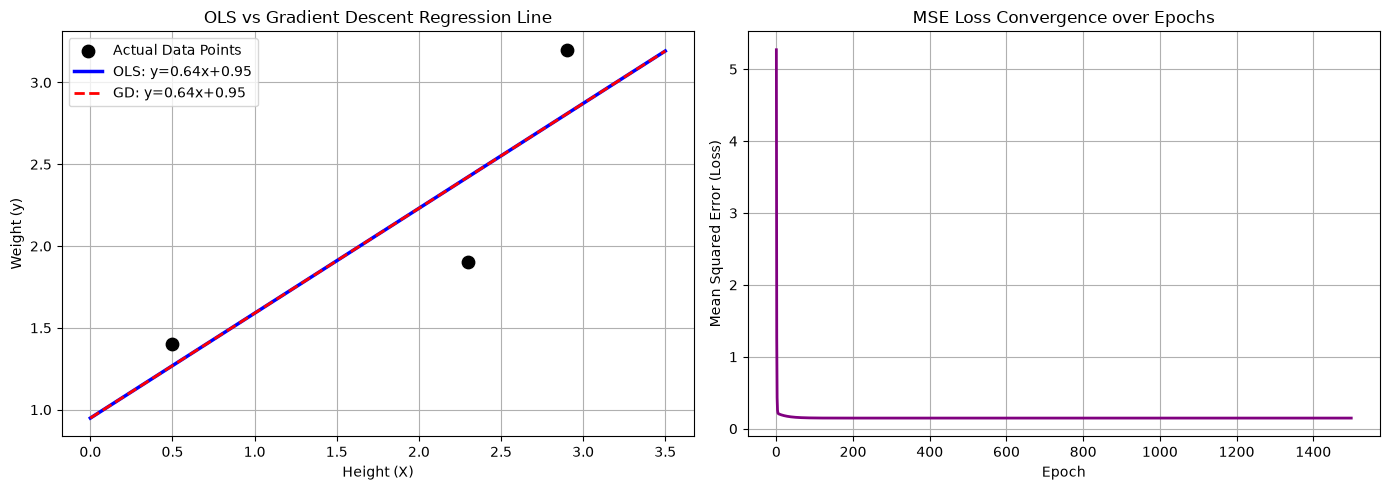

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Regression Fit Comparison
axes[0].scatter(X, y, color="black", s=80, label="Actual Data Points", zorder=5)

# Generate smooth x-axis line
x_vals = np.linspace(0, 3.5, 100)
axes[0].plot(x_vals, m_ols * x_vals + c_ols, color="blue", linewidth=2.5, label=f"OLS: y={m_ols:.2f}x+{c_ols:.2f}")
axes[0].plot(x_vals, m_gd * x_vals + c_gd, color="red", linestyle="--", linewidth=2, label=f"GD: y={m_gd:.2f}x+{c_gd:.2f}")

axes[0].set_title("OLS vs Gradient Descent Regression Line")
axes[0].set_xlabel("Height (X)")
axes[0].set_ylabel("Weight (y)")
axes[0].legend()
axes[0].grid(True)

# Subplot 2: Loss Convergence Curve
axes[1].plot(range(len(losses)), losses, color="purple", linewidth=2)
axes[1].set_title("MSE Loss Convergence over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Mean Squared Error (Loss)")
axes[1].grid(True)

plt.tight_layout()
plt.show()